In [10]:
import numpy as np
import matplotlib.pyplot as plt

In [11]:
x=np.array([1,2,3,4,5,6,7])
y=np.array([2,2,8,3,6,4,5])

In [12]:
n = len(x)
#=========================
#initialize parameters
#========================
w = 0
b = 0
# np.random.seed(42)
# w = np.random.rand()
# b = np.random.rand()
learning_rate = 0.01
epochs = 100
cost_values = []
print(f"initail w : {w}")
print(f"initail b : {b}")
print(f"learning_rate : {learning_rate}")
print(f"epochs  : {epochs}")
print("Training........................")
 
 
 

initail w : 0
initail b : 0
learning_rate : 0.01
epochs  : 100
Training........................


In [13]:
#=======================
#Gradient Descent   
#======================
for i in range(epochs):
    y_hat = w * x + b
    error = y_hat - y
    #Gradients
    d_w = np.mean(error * x)
    d_b = np.mean(error)
    #update parameters
    w -= learning_rate * d_w
    b -= learning_rate * d_b
    #new line prediction
    y_hat = w*x +b   
    #cost
    cost = 0.5* np.mean((y_hat - y )**2)
    cost_values.append(cost)
    
    if (i +1) % 100 == 0 or i == 0:
        print(f"Epoch {i+1}:"
              f"cost = {cost},"
              f"w = {w}, "
              f"b = {b} ")
    
    
    
    
    
 

Epoch 1:cost = 7.983020408163265,w = 0.18714285714285717, b = 0.04285714285714286 
Epoch 100:cost = 2.229738659285301,w = 0.814622434070692, b = 0.6257288692514539 


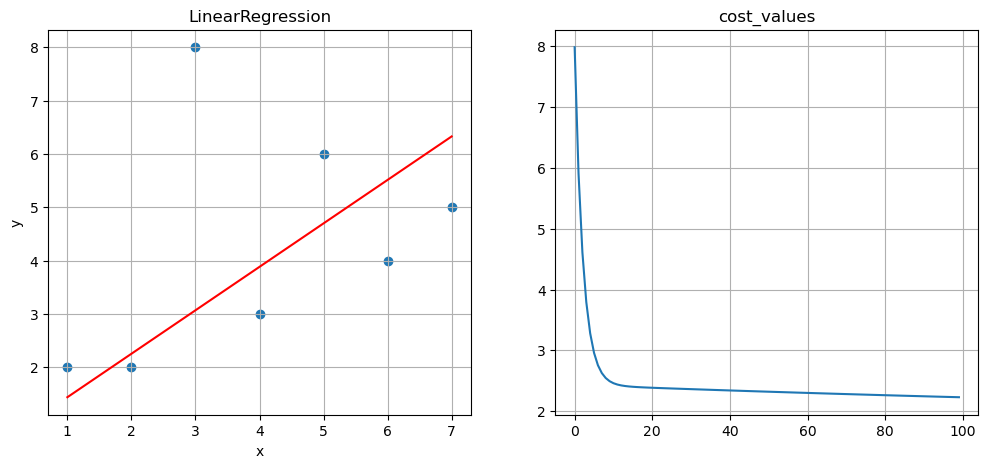

In [14]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.scatter(x,y)
plt.plot(x, w*x + b, 'r-')
plt.title("LinearRegression")
plt.xlabel("x")
plt.ylabel("y")
plt.grid()
 
plt.subplot(1,2,2)
plt.plot(cost_values)
plt.title("cost_values")
 
plt.grid()
 

In [26]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score,root_mean_squared_error
 
 
data = pd.read_csv(r"C:\Users\DELL\Downloads\Salary_Data.csv")
 
data.head()
 

 

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


d:\mahmoud\programs\anaconda\anacondaa\Lib\site-packages\seaborn\axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


<Figure size 300x400 with 0 Axes>

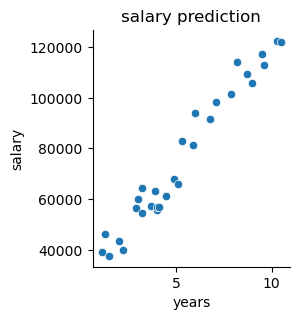

In [18]:
plt.figure(figsize=(3,4))
sns.pairplot(data, x_vars=["YearsExperience"], y_vars=["Salary"],size = 3, kind="scatter")
plt.xlabel("years")
plt.ylabel("salary")
plt.title("salary prediction")
plt.show()

In [19]:
x=data.iloc[:,:-1]
y=data.iloc[:,1]

In [20]:
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=.8,random_state=42)

In [21]:
y_train

28    122391.0
24    109431.0
12     56957.0
0      39343.0
4      39891.0
16     66029.0
5      56642.0
13     57081.0
11     55794.0
22    101302.0
1      46205.0
2      37731.0
25    105582.0
3      43525.0
21     98273.0
26    116969.0
18     81363.0
29    121872.0
20     91738.0
7      54445.0
10     63218.0
14     61111.0
19     93940.0
6      60150.0
Name: Salary, dtype: float64

In [22]:
lin_reg=LinearRegression()
lin_reg.fit(x_train,y_train)
y_hat=lin_reg.predict(x_train)

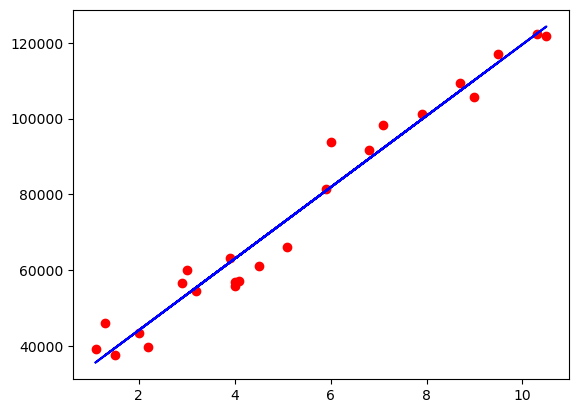

In [24]:
plt.scatter(x_train,y_train,color='red')
plt.plot(x_train,y_hat,color='blue')

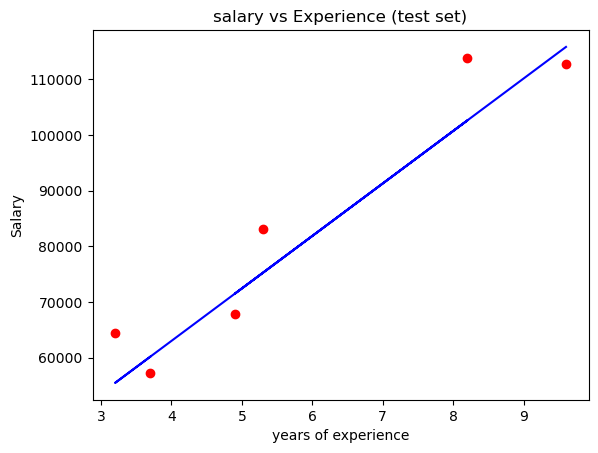

In [25]:
y_hat_test = lin_reg.predict(x_test)
 
 
plt.scatter(x_test, y_test, color = 'red')
plt.plot(x_test, y_hat_test, color = 'blue')
plt.title("salary vs Experience (test set)")
plt.xlabel('years of experience')
plt.ylabel('Salary')
plt.show()
 

In [27]:
mse=mean_squared_error(y_test,y_hat_test)
rmse=root_mean_squared_error(y_test,y_hat_test)
print(rmse)

7059.04362190151


In [28]:
r2=r2_score(y_test,y_hat_test)
print(r2)

0.9024461774180497
